## IEEE33 — Cyclic trading topology

IEEE33 Cyclic Network Comparison - 4, 8, 16, 32 Prosumers 

Set Up:
- Optimization horizon: 48 hours
- Evaluation horizon: first 24 hours
- Temporal resolution: 30 minutes
- Disagreement point: individual no-trade optimization
- Centralized social-cost minimization and distributed ADMM

In [20]:
# imports
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

from IPython.display import display

In [14]:
# settings 
ROOT = Path.cwd() / 'structures'

POPULATIONS = [4, 8, 16, 32]
TOPOLOGY = 'cyclic'
CASE = 'centralized'

TOL = 1e-6
COLORS = dict(zip(POPULATIONS, plt.cm.viridis(
    np.linspace(0.15, 0.85, len(POPULATIONS))
)))

plt.rcParams.update({
    'figure.figsize': (10, 4),
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.2,
})

pd.set_option('display.max_columns', 30)
pd.set_option('display.precision', 5)

In [15]:
def read_json(path):
    with open(path) as f:
        return json.load(f)


def read_baseline(obj):
    if isinstance(obj, list):
        return np.asarray(obj, dtype=float)

    for key in ['J_nt', 'costs', 'no_trade_costs', 'J']:
        if key in obj:
            return np.asarray(obj[key], dtype=float)

    raise ValueError(f'Unknown baseline format: {list(obj)}')


rows = []
issues = []

for N in POPULATIONS:

    folder = ROOT / f'ieee33_{N}_{TOPOLOGY}' / 'results'

    for date_dir in sorted(folder.glob('2016-*')):

        if not date_dir.is_dir():
            continue

        result_path = date_dir / f'{CASE}.json'
        baseline_path = date_dir / 'no_trade.json'

        if not result_path.exists() or not baseline_path.exists():
            issues.append((N, date_dir.name, 'Incomplete'))
            continue

        result = read_json(result_path)
        J = np.asarray(result['costs'], dtype=float)
        J_nt = read_baseline(read_json(baseline_path))

        assert J.shape == J_nt.shape == (N,)

        # Protect against mixing old and new results
        if 'costs_full' not in result:
            issues.append((N, date_dir.name, 'Old cost format'))
            continue

        J_full = np.asarray(result['costs_full'], dtype=float)

        if np.asarray(result['buy']).shape != (N, 96):
            issues.append((N, date_dir.name, 'Unexpected horizon'))
            continue

        if not np.isfinite(J).all() or not np.isfinite(J_nt).all():
            issues.append((N, date_dir.name, 'Nonfinite costs'))
            continue

        for i in range(N):

            rows.append({
                'N': N,
                'date': pd.Timestamp(date_dir.name),
                'prosumer': f'P{i+1}',
                'J': J[i],
                'J_nt': J_nt[i],
                'J_full': J_full[i],
            })

df = pd.DataFrame(rows)

assert not df.empty, 'No compatible results found.'

df['gain'] = df['J_nt'] - df['J']

# Replicate current metrics.py convention
df['d'] = df['gain'] / np.where(
    df['J_nt'].abs() > 1e-9,
    df['J_nt'].abs(),
    1.0
)

df['month'] = df['date'].dt.month

print('Available dates:')
display(df.groupby('N')['date'].agg(['count', 'nunique', 'min', 'max']))

print('Skipped or incompatible results:')
display(pd.DataFrame(issues, columns=['N', 'date', 'reason']))

display(df.head())

Available dates:


,count,nunique,min,max
N,,,,
4,144,36,2016-01-07,2016-12-21
8,288,36,2016-01-07,2016-12-21
16,576,36,2016-01-07,2016-12-21
32,1152,36,2016-01-07,2016-12-21


Skipped or incompatible results:


,N,date,reason
0,4,2016-01-15,Incomplete
1,4,2016-02-15,Incomplete
2,4,2016-03-15,Incomplete
3,4,2016-04-15,Incomplete
4,4,2016-05-15,Incomplete
5,4,2016-06-15,Incomplete
6,4,2016-07-15,Incomplete
7,4,2016-08-15,Incomplete
8,4,2016-09-15,Incomplete
9,4,2016-10-15,Incomplete


,N,date,prosumer,J,J_nt,J_full,gain,d,month
0,4,2016-01-07,P1,9.55805,9.55805,16.21226,-6.02650e-09,-6.30515e-10,1
1,4,2016-01-07,P2,55.00790,55.00790,109.86433,-7.45743e-08,-1.35570e-09,1
2,4,2016-01-07,P3,2.52852,2.52852,5.11654,4.24105e-08,1.67729e-08,1
3,4,2016-01-07,P4,10.88520,10.88520,22.84841,-3.38613e-08,-3.11076e-09,1
4,4,2016-01-14,P1,3.89090,3.61583,6.66096,-2.75061e-01,-7.60713e-02,1


In [16]:
date_sets = [
    set(df.loc[df['N'] == N, 'date'])
    for N in POPULATIONS
]

common_dates = sorted(set.intersection(*date_sets))

assert common_dates, 'No dates shared by all populations.'

df_common = df[df['date'].isin(common_dates)].copy()

print(f'Common dates: {len(common_dates)}')
print(f'From: {common_dates[0]:%Y-%m-%d}')
print(f'To:   {common_dates[-1]:%Y-%m-%d}')

coverage = (
    df.groupby(['N', 'month'])['date']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

display(coverage)

Common dates: 36
From: 2016-01-07
To:   2016-12-21


month,1,2,3,4,5,6,7,8,9,10,11,12
N,,,,,,,,,,,,
4,3,3,3,3,3,3,3,3,3,3,3,3
8,3,3,3,3,3,3,3,3,3,3,3,3
16,3,3,3,3,3,3,3,3,3,3,3,3
32,3,3,3,3,3,3,3,3,3,3,3,3


## calculate fairness metrics

In [17]:
def jain(x):
    x = np.asarray(x, dtype=float)
    s2 = np.sum(x**2)

    return np.nan if s2 < 1e-12 else (
        np.sum(x)**2 / (len(x) * s2)
    )


def calculate_metrics(group):

    J = group['J'].to_numpy()
    J_nt = group['J_nt'].to_numpy()
    g = group['gain'].to_numpy()
    d = group['d'].to_numpy()

    raw_product = np.prod(g)

    return {
        'TW': g.sum() / J_nt.sum()
              if J_nt.sum() >= 1e-9 else np.nan,

        'NBS': raw_product if np.all(g > 0) else 0.0,
        'NBS_raw': raw_product,

        'MM': J.max(),
        'JI': jain(J),
        'Var': np.var(J),

        'd_MM': d.min(),
        'd_JI': jain(d),
        'd_Var': np.var(d),

        # Additional diagnostics
        'total_gain': g.sum(),
        'mean_gain': g.mean(),
        'min_gain': g.min(),
        'max_gain': g.max(),

        'n_winners': np.sum(g > TOL),
        'n_losers': np.sum(g < -TOL),
        'n_neutral': np.sum(np.abs(g) <= TOL),

        'loser_fraction': np.mean(g < -TOL),
        'IR': np.all(g >= -TOL),

        'negative_baselines': np.sum(J_nt < 0),
        'min_abs_baseline': np.abs(J_nt).min(),

        # Comparable across population sizes
        'NBS_geo': np.exp(np.log(g).mean())
                   if np.all(g > 0) else 0.0,

        'log10_abs_NBS_raw': np.log10(np.abs(g)).sum()
                             if np.all(g != 0) else np.nan,
    }


daily = pd.DataFrame([
    {
        'N': N,
        'date': date,
        **calculate_metrics(group)
    }
    for (N, date), group in df.groupby(['N', 'date'])
])

daily_common = daily[daily['date'].isin(common_dates)].copy()

display(daily.head())

,N,date,TW,NBS,NBS_raw,MM,JI,Var,d_MM,d_JI,d_Var,total_gain,mean_gain,min_gain,max_gain,n_winners,n_losers,n_neutral,loser_fraction,IR,negative_baselines,min_abs_baseline,NBS_geo,log10_abs_NBS_raw
0,4,2016-01-07,-9.23979e-10,0.0,-6.45402e-31,55.00790,0.46889,430.47479,-3.11076e-09,NaN,6.47899e-17,-7.20516e-08,-1.80129e-08,-7.45743e-08,4.24105e-08,0,0,4,0.00,True,0,2.52852,0.0,-30.19017
1,4,2016-01-14,4.03218e-03,0.0,-6.45338e-04,57.67702,0.37372,531.11694,-7.60713e-02,0.05087,1.51878e-03,2.88299e-01,7.20747e-02,-2.75061e-01,4.11804e-01,3,1,0,0.25,False,0,3.48497,0.0,-3.19021
2,4,2016-01-21,1.10141e-03,0.0,6.26870e-03,51.28012,0.46308,374.05955,-1.09803e-01,0.06192,3.31461e-03,7.92188e-02,1.98047e-02,-8.15057e-01,7.96008e-01,2,2,0,0.50,False,0,3.75444,0.0,-2.20282
3,4,2016-02-07,1.42178e-02,0.0,1.86807e-04,7.73066,0.81648,5.08650,-3.81259e-02,0.18556,1.96848e-03,2.74438e-01,6.86096e-02,-2.83914e-01,3.45457e-01,2,2,0,0.50,False,0,2.34592,0.0,-3.72861
4,4,2016-02-14,1.78373e-03,0.0,-2.22332e-07,14.49902,0.76621,20.67980,-1.34998e-03,0.52783,1.06373e-05,5.88428e-02,1.47107e-02,-1.95469e-02,4.57084e-02,3,1,0,0.25,False,0,1.65698,0.0,-6.65300


In [18]:
METRICS = [
    'TW', 'NBS', 'MM', 'JI', 'Var',
    'd_MM', 'd_JI', 'd_Var'
]

print('All available dates — descriptive only')
display(daily.groupby('N')[METRICS].mean())

print('Common dates — comparable sample')
display(daily_common.groupby('N')[METRICS].mean())

print('Common dates — median metrics')
display(daily_common.groupby('N')[METRICS].median())

All available dates — descriptive only


,TW,NBS,MM,JI,Var,d_MM,d_JI,d_Var
N,,,,,,,,
4,0.03858,1.64812e-02,36.00207,0.34019,265.03389,-0.30142,0.33248,0.23059
8,0.03114,2.85576e-03,44.98653,0.34805,284.54706,-1.70365,0.23674,4.62587
16,0.02259,2.61421e-06,50.08032,0.34544,315.96496,-2.07546,0.14032,2.75229
32,0.02212,0.00000e+00,50.95044,0.29560,292.22020,-1.71727,0.10842,219.55998


Common dates — comparable sample


,TW,NBS,MM,JI,Var,d_MM,d_JI,d_Var
N,,,,,,,,
4,0.03858,1.64812e-02,36.00207,0.34019,265.03389,-0.30142,0.33248,0.23059
8,0.03114,2.85576e-03,44.98653,0.34805,284.54706,-1.70365,0.23674,4.62587
16,0.02259,2.61421e-06,50.08032,0.34544,315.96496,-2.07546,0.14032,2.75229
32,0.02212,0.00000e+00,50.95044,0.29560,292.22020,-1.71727,0.10842,219.55998


Common dates — median metrics


,TW,NBS,MM,JI,Var,d_MM,d_JI,d_Var
N,,,,,,,,
4,0.02345,0.0,36.18679,0.31047,223.75246,-0.01899,0.26079,0.01324
8,0.01481,0.0,45.19010,0.31297,284.34932,-0.12548,0.20187,0.03945
16,0.01421,0.0,48.43821,0.31999,303.31566,-0.28043,0.09111,0.04063
32,0.01647,0.0,49.24031,0.26734,275.90557,-0.41806,0.03640,0.04550


### Plots

In [38]:
# Helpers
daily_common['date'] = pd.to_datetime(daily_common['date'])
if 'date' in df_common.columns:
    df_common['date'] = pd.to_datetime(df_common['date'])

POPULATIONS = sorted(daily_common['N'].unique())

def grouped_mean_median(frame, metric):
    g = frame.groupby('N')[metric]
    return g.mean().reindex(POPULATIONS), g.median().reindex(POPULATIONS)

def boxplot_by_N(ax, frame, metric, title, ylabel=None, logy=False):
    data = [frame.loc[frame['N'] == N, metric].dropna().values for N in POPULATIONS]
    ax.boxplot(data, labels=[str(N) for N in POPULATIONS], showfliers=True)
    ax.set_title(title)
    ax.set_xlabel('Number of prosumers')
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if logy:
        ax.set_yscale('symlog', linthresh=1e-3)
    ax.axhline(0, color='black', linewidth=0.8)

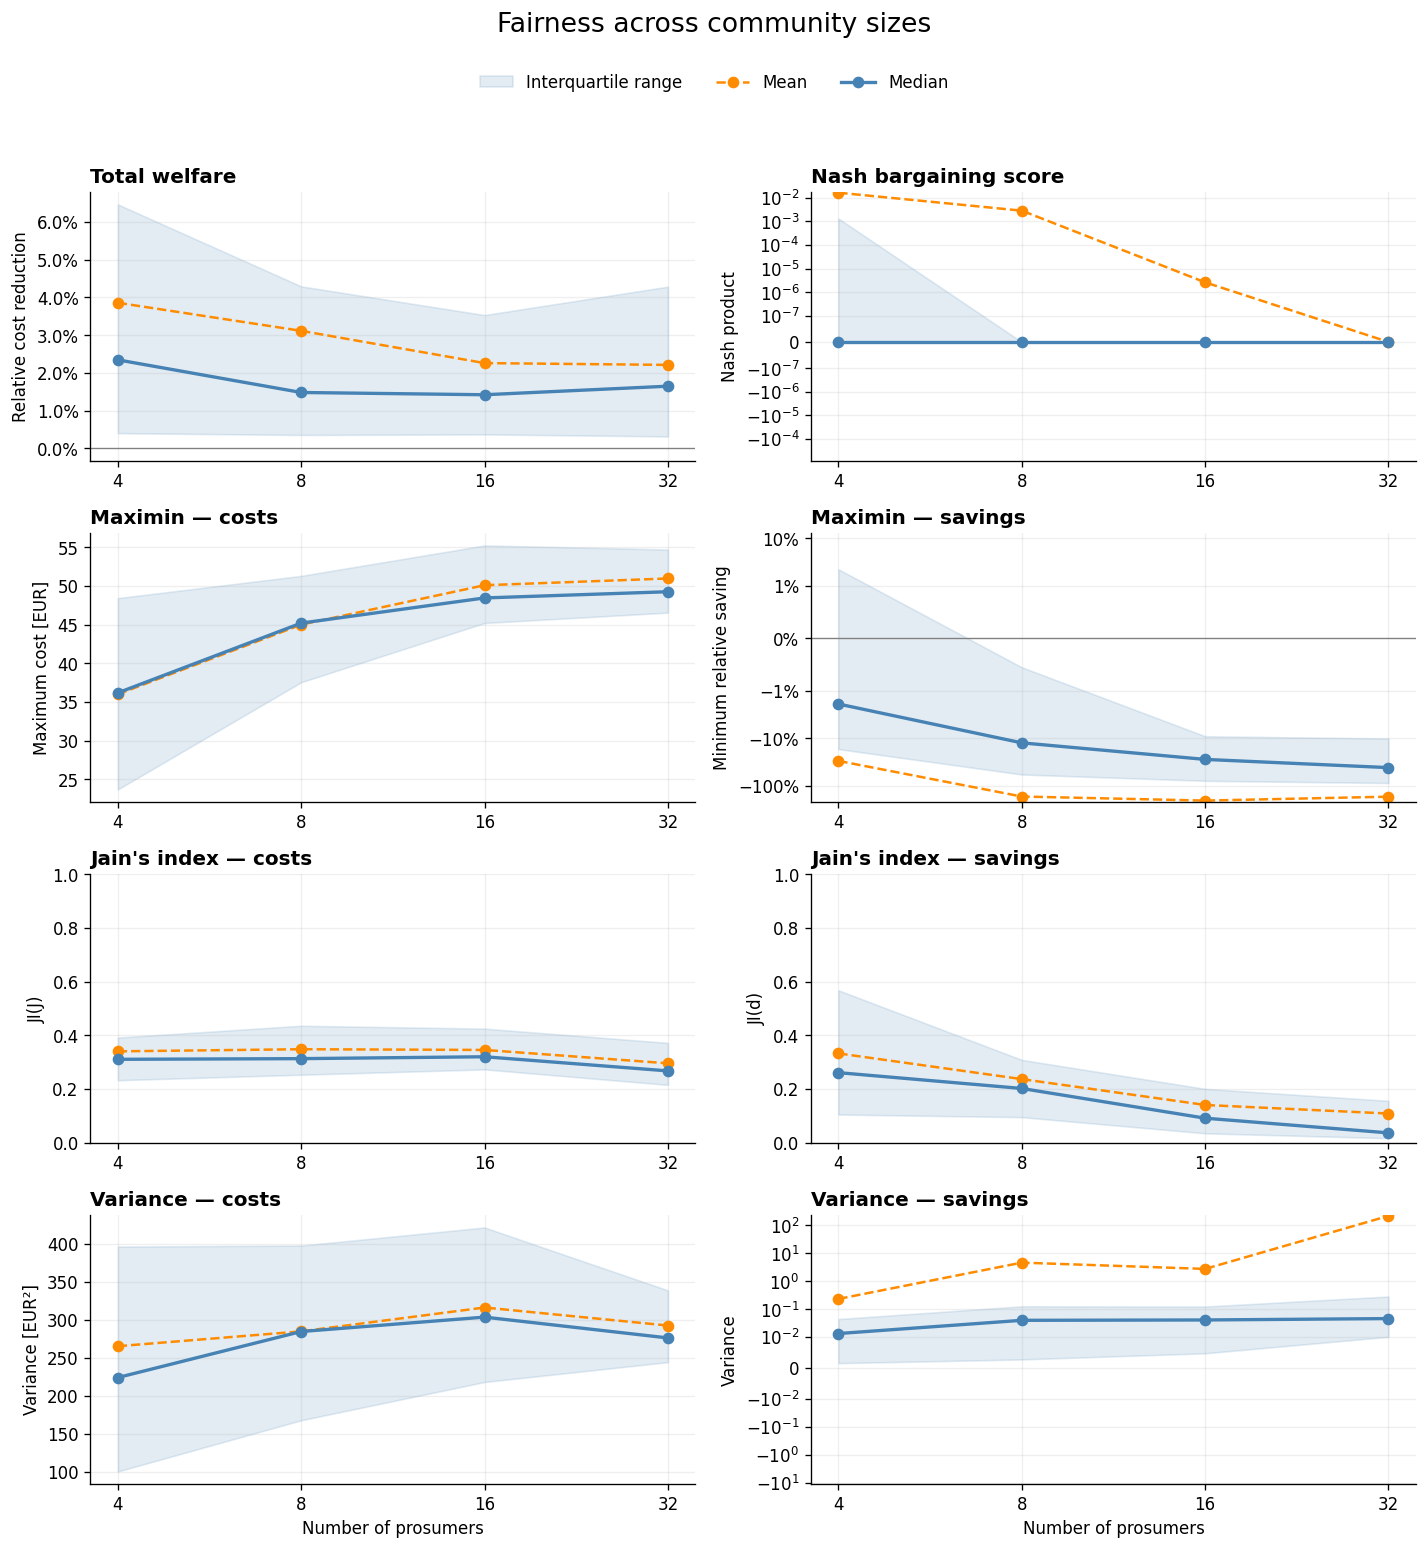

In [39]:
from matplotlib.ticker import PercentFormatter
from matplotlib.lines import Line2D

specs = [
    ('TW',    'Total welfare',                'Relative cost reduction', 'linear'),
    ('NBS',   'Nash bargaining score',         'Nash product',            'symlog'),
    ('MM',    'Maximin — costs',               'Maximum cost [EUR]',     'linear'),
    ('d_MM',  'Maximin — savings',             'Minimum relative saving', 'symlog'),
    ('JI',    "Jain's index — costs",          'JI(J)',                   'linear'),
    ('d_JI',  "Jain's index — savings",        'JI(d)',                   'linear'),
    ('Var',   'Variance — costs',              'Variance [EUR²]',         'linear'),
    ('d_Var', 'Variance — savings',            'Variance',                'symlog'),
]

fig, axes = plt.subplots(4, 2, figsize=(12, 13))

x = np.arange(len(POPULATIONS))

for ax, (metric, title, ylabel, scale) in zip(axes.flat, specs):

    stats = daily_common.groupby('N')[metric]

    mean = stats.mean().reindex(POPULATIONS)
    median = stats.median().reindex(POPULATIONS)
    q25 = stats.quantile(0.25).reindex(POPULATIONS)
    q75 = stats.quantile(0.75).reindex(POPULATIONS)

    ax.fill_between(
        x, q25, q75,
        color='steelblue', alpha=0.15,
        label='Interquartile range'
    )

    ax.plot(
        x, mean, 'o--',
        color='darkorange', linewidth=1.5,
        label='Mean'
    )

    ax.plot(
        x, median, 'o-',
        color='steelblue', linewidth=2,
        label='Median'
    )

    ax.set_xticks(x, POPULATIONS)
    ax.set_title(title, loc='left', fontweight='bold')
    ax.set_ylabel(ylabel)

    if scale == 'symlog':
        threshold = {
            'NBS': 1e-7,
            'd_MM': 0.01,
            'd_Var': 0.01
        }[metric]

        ax.set_yscale('symlog', linthresh=threshold)

    if metric in ['TW', 'd_MM']:
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.axhline(0, color='grey', linewidth=0.8)

    if metric in ['JI', 'd_JI']:
        ax.set_ylim(0, 1)

for ax in axes[-1]:
    ax.set_xlabel('Number of prosumers')

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 0.96),
    ncol=3, frameon=False
)

fig.suptitle(
    'Fairness across community sizes',
    fontsize=16, y=0.99
)

fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

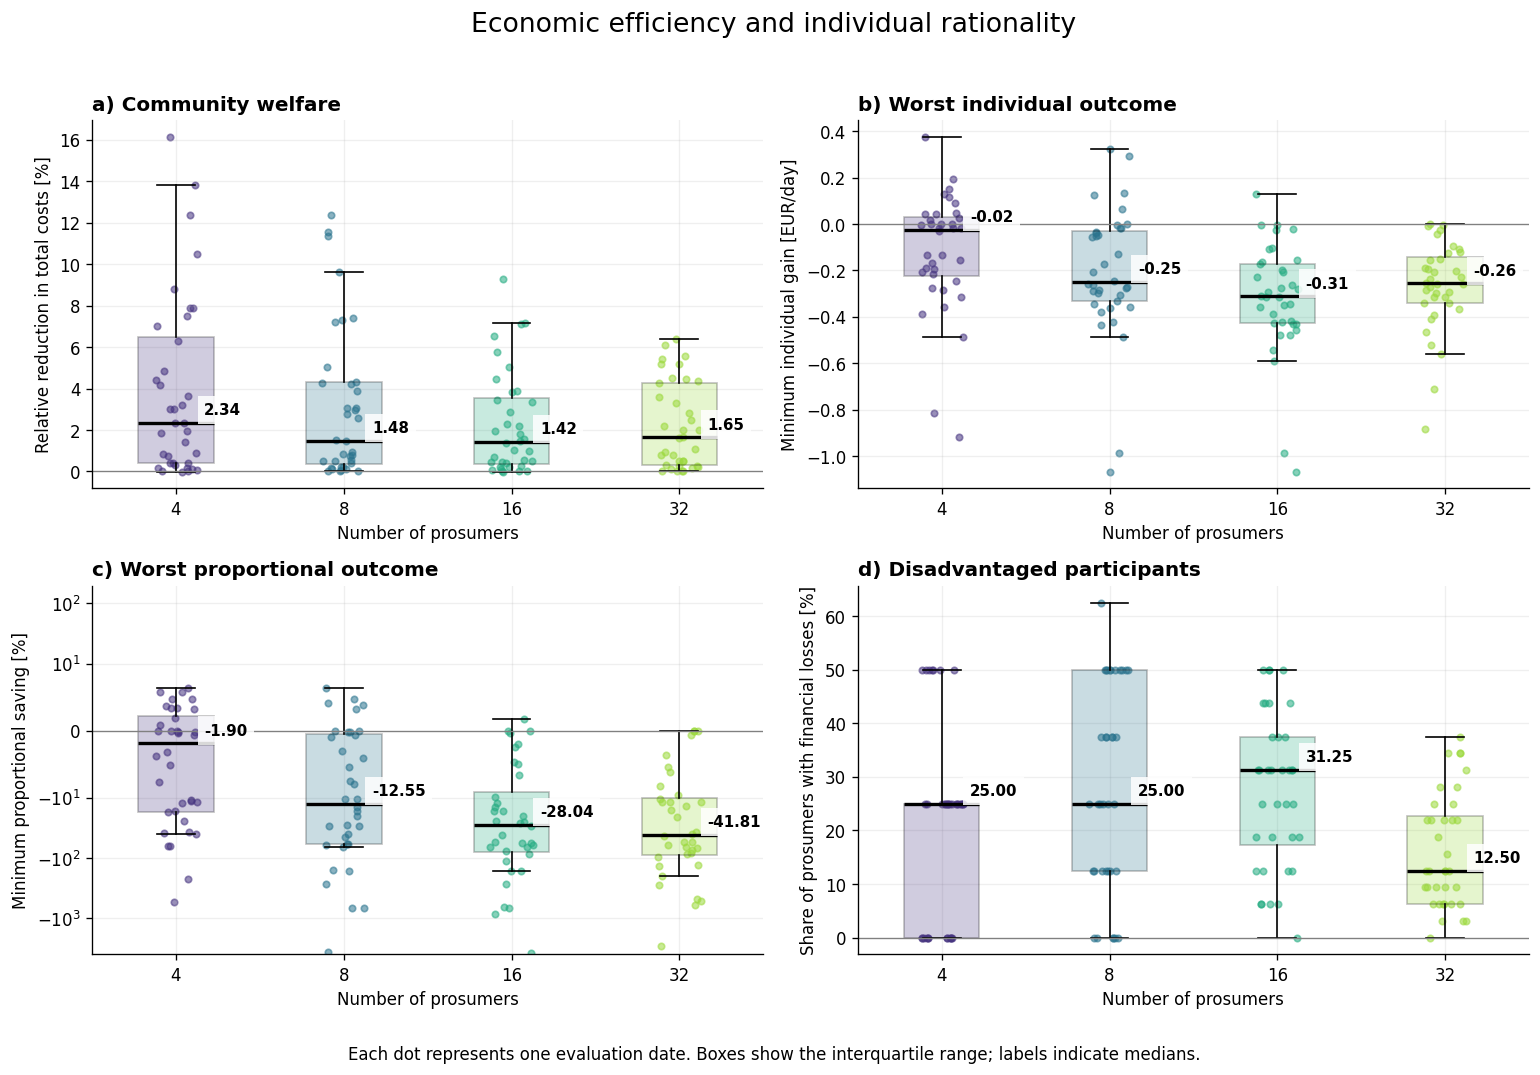

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

specs = [
    ('TW', 'a) Community welfare',
     'Relative reduction in total costs [%]', 100, False),

    ('min_gain', 'b) Worst individual outcome',
     'Minimum individual gain [EUR/day]', 1, False),

    ('d_MM', 'c) Worst proportional outcome',
     'Minimum proportional saving [%]', 100, True),

    ('loser_fraction', 'd) Disadvantaged participants',
     'Share of prosumers with financial losses [%]', 100, False),
]

rng = np.random.default_rng(42)

for ax, (metric, title, ylabel, scale, log) in zip(axes.flat, specs):

    for pos, N in enumerate(POPULATIONS, start=1):

        values = (
            daily_common.loc[daily_common['N'] == N, metric]
            .dropna().to_numpy() * scale
        )

        ax.boxplot(
            values,
            positions=[pos],
            widths=0.45,
            patch_artist=True,
            showfliers=False,
            boxprops=dict(
                facecolor=COLORS[N], alpha=0.25
            ),
            medianprops=dict(
                color='black', linewidth=2
            )
        )

        ax.scatter(
            pos + rng.uniform(-0.13, 0.13, len(values)),
            values,
            color=COLORS[N],
            alpha=0.55,
            s=15
        )

        median = np.median(values)

        ax.annotate(
            f'{median:.2f}',
            xy=(pos, median),
            xytext=(17, 5),
            textcoords='offset points',
            fontsize=9,
            fontweight='bold',
            bbox=dict(
                facecolor='white',
                edgecolor='none',
                alpha=0.85
            )
        )

    ax.set_xticks(range(1, len(POPULATIONS) + 1), POPULATIONS)
    ax.set_xlabel('Number of prosumers')
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left', fontweight='bold')

    ax.axhline(0, color='grey', linewidth=0.8)

    if log:
        ax.set_yscale('symlog', linthresh=10)

fig.suptitle(
    'Economic efficiency and individual rationality',
    fontsize=16
)

fig.text(
    0.5, 0.01,
    'Each dot represents one evaluation date. '
    'Boxes show the interquartile range; '
    'labels indicate medians.',
    ha='center', fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()

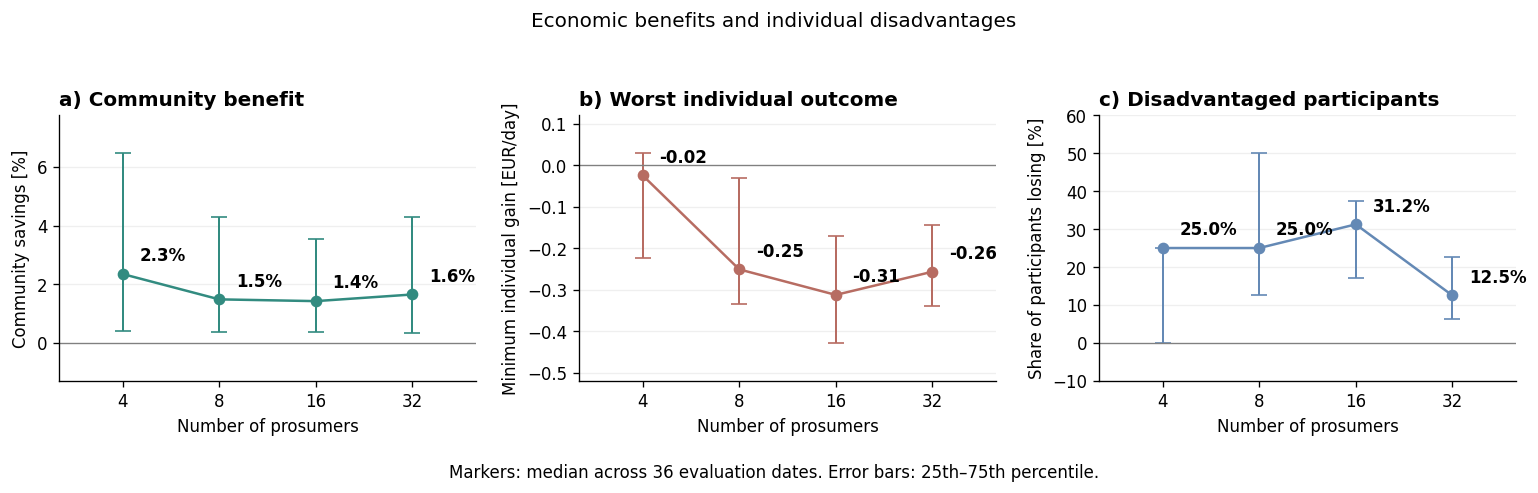

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

specs = [
    ('TW',
     'a) Community benefit',
     'Community savings [%]',
     100, '#328b80'),

    ('min_gain',
     'b) Worst individual outcome',
     'Minimum individual gain [EUR/day]',
     1, '#b76c62'),

    ('loser_fraction',
     'c) Disadvantaged participants',
     'Share of participants losing [%]',
     100, '#6489b5')
]

x = np.arange(len(POPULATIONS))

for ax, (metric, title, ylabel, scale, color) in zip(
    axes, specs
):

    grouped = daily_common.groupby('N')[metric]

    median = grouped.median().reindex(POPULATIONS) * scale
    q25 = grouped.quantile(0.25).reindex(POPULATIONS) * scale
    q75 = grouped.quantile(0.75).reindex(POPULATIONS) * scale

    ax.errorbar(
        x, median,
        yerr=[median - q25, q75 - median],
        fmt='o-',
        color=color,
        linewidth=1.5,
        markersize=6,
        capsize=5,
        elinewidth=1.2
    )

    for pos, value in zip(x, median):

        ax.annotate(
            f'{value:.2f}' if scale == 1
            else f'{value:.1f}%',
            xy=(pos, value),
            xytext=(10, 8),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold'
        )

    ax.set_xticks(x, POPULATIONS)
    ax.set_xlabel('Number of prosumers')
    ax.set_ylabel(ylabel)
    ax.set_title(title, loc='left', fontweight='bold')

    ax.axhline(0, color='grey', linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.margins(x=0.22, y=0.2)

fig.suptitle('Economic benefits and individual disadvantages')

fig.text(
    0.5, 0.01,
    'Markers: median across 36 evaluation dates. '
    'Error bars: 25th–75th percentile.',
    ha='center', fontsize=10
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])
plt.show()

In [28]:
from populations.ieee33 import _PROSUMERS_32

prosumer_labels = {
    f'P{i+1}': f"P{i+1:02d} — {p['name']}"
    for i, p in enumerate(_PROSUMERS_32)
}

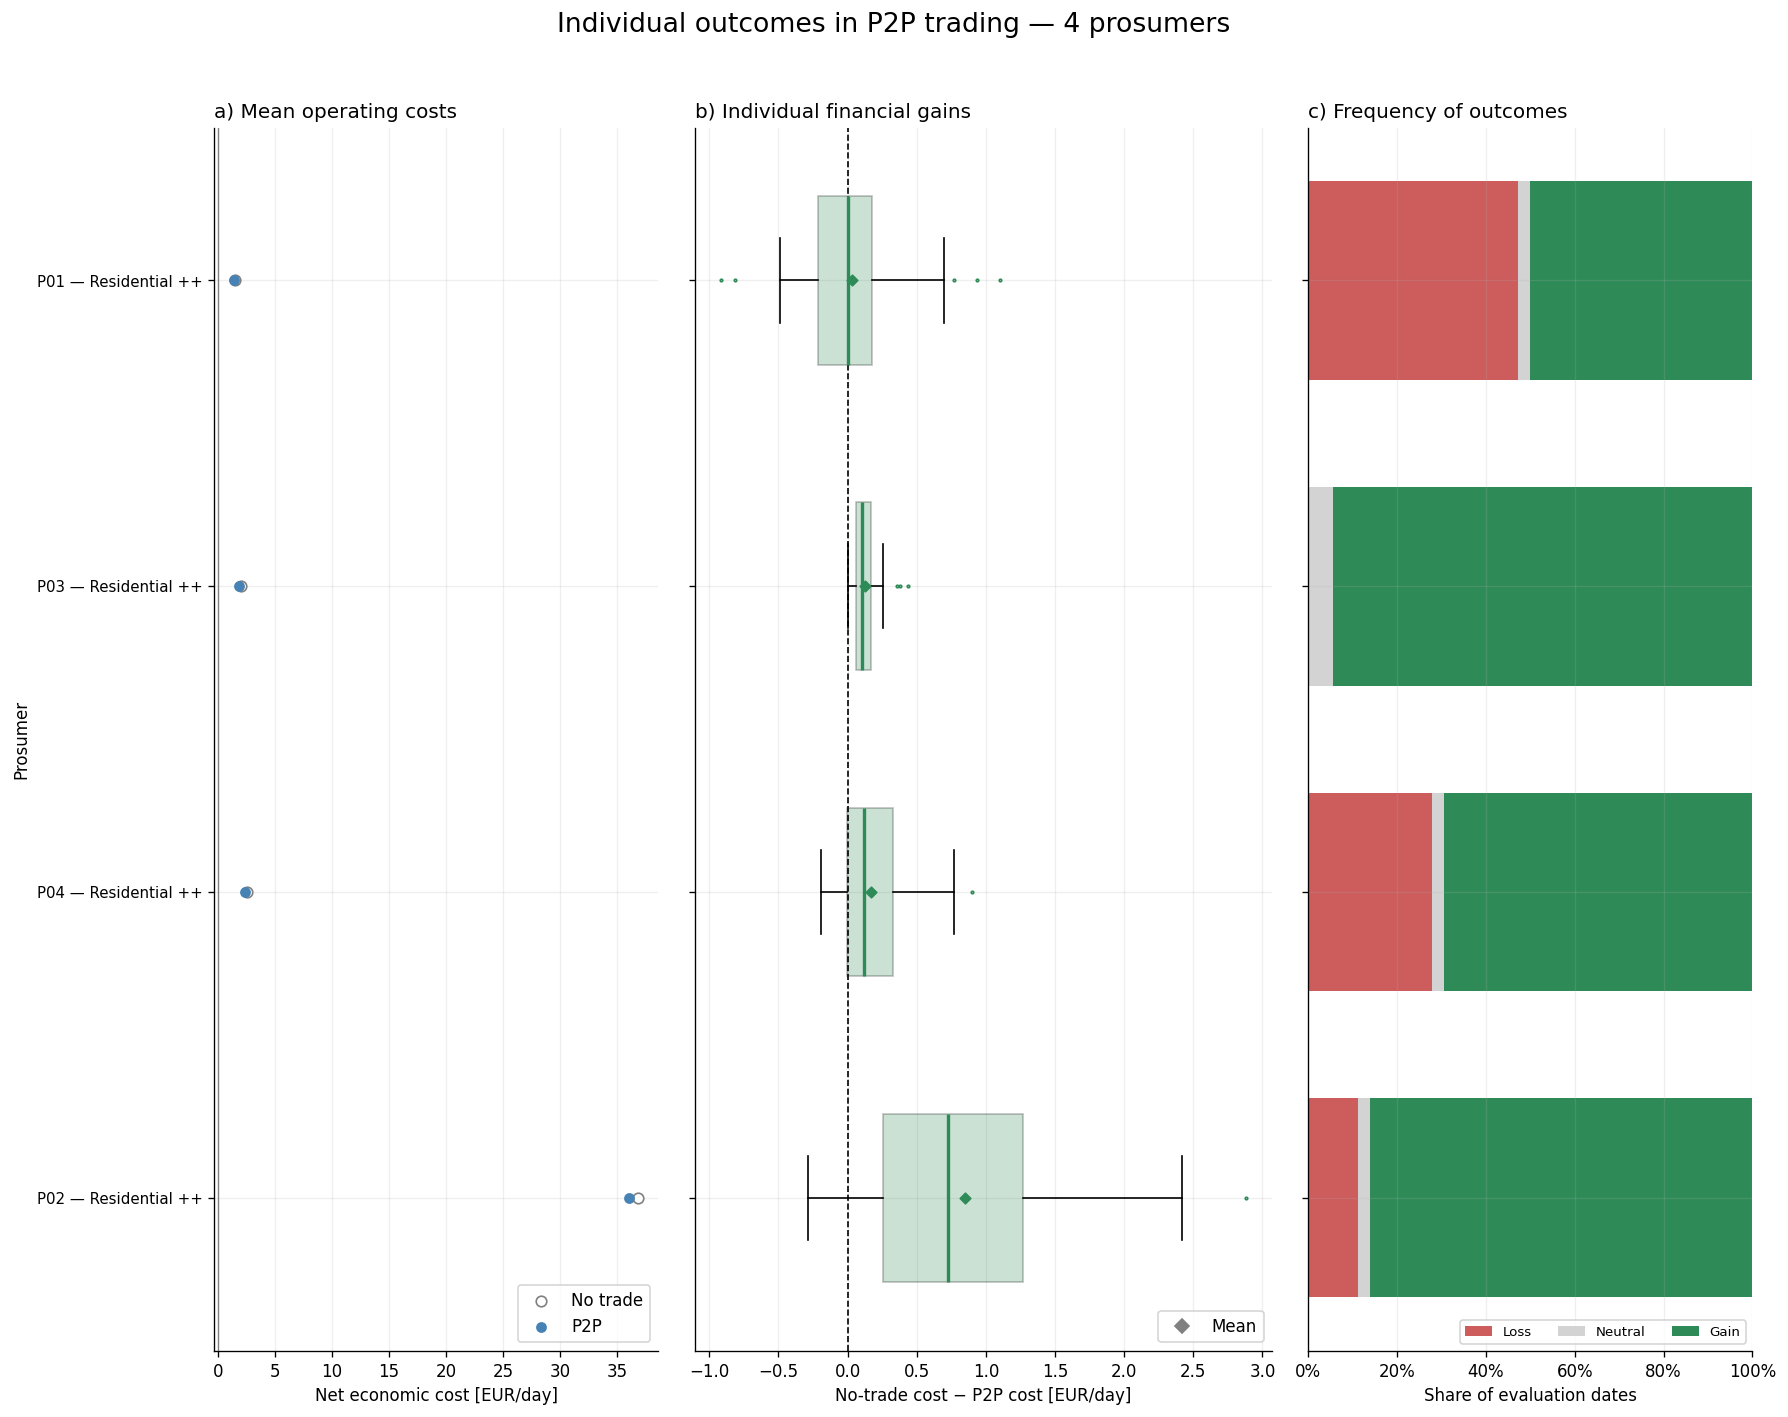

In [35]:
N = 4

sub = df_common[df_common['N'] == N].copy()

# Use the same tolerance as the fairness diagnostics
sub['winner'] = sub['gain'] > TOL
sub['loser'] = sub['gain'] < -TOL
sub['neutral'] = sub['gain'].abs() <= TOL

individual = sub.groupby('prosumer').agg(
    baseline_cost=('J_nt', 'mean'),
    p2p_cost=('J', 'mean'),
    mean_gain=('gain', 'mean'),
    median_gain=('gain', 'median'),
    winner_share=('winner', 'mean'),
    loser_share=('loser', 'mean'),
    neutral_share=('neutral', 'mean')
)

# Sort from most disadvantaged to most benefited
individual = individual.sort_values('mean_gain')

order = individual.index.tolist()
y = np.arange(len(order))

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 12),
    sharey=True,
    gridspec_kw={'width_ratios': [1, 1.3, 1]}
)

# ── A. Costs before and after P2P ─────────────────

ax = axes[0]

ax.hlines(
    y,
    individual['baseline_cost'],
    individual['p2p_cost'],
    color='grey', alpha=0.6
)

ax.scatter(
    individual['baseline_cost'], y,
    facecolors='white',
    edgecolors='grey',
    s=40, label='No trade', zorder=3
)

ax.scatter(
    individual['p2p_cost'], y,
    color='steelblue',
    s=30, label='P2P', zorder=3
)

ax.set_title('a) Mean operating costs', loc='left')
ax.set_xlabel('Net economic cost [EUR/day]')
ax.axvline(0, color='grey', linewidth=0.8)
ax.legend(loc='lower right')


# ── B. Distribution of individual gains ──────────

ax = axes[1]

for pos, p in enumerate(order):

    gains = sub.loc[sub['prosumer'] == p, 'gain'].values

    color = (
        'seagreen'
        if individual.loc[p, 'mean_gain'] >= 0
        else 'indianred'
    )

    ax.boxplot(
        gains,
        positions=[pos],
        vert=False,
        widths=0.55,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.25),
        medianprops=dict(color=color, linewidth=2),
        flierprops=dict(
            marker='.',
            markersize=3,
            markeredgecolor=color
        )
    )

    ax.scatter(
        gains.mean(), pos,
        marker='D', s=20,
        color=color, zorder=4
    )

ax.axvline(0, color='black', linestyle='--', linewidth=1)

ax.set_title('b) Individual financial gains', loc='left')
ax.set_xlabel('No-trade cost − P2P cost [EUR/day]')

ax.legend(
    handles=[
        Line2D([], [], marker='D', linestyle='none',
               color='grey', label='Mean')
    ],
    loc='lower right'
)


# ── C. Frequency of winning and losing ────────────

ax = axes[2]

left = np.zeros(len(individual))

for metric, color, label in [
    ('loser_share', 'indianred', 'Loss'),
    ('neutral_share', 'lightgrey', 'Neutral'),
    ('winner_share', 'seagreen', 'Gain')
]:

    values = individual[metric].values

    ax.barh(
        y, values, left=left,
        color=color, height=0.65,
        label=label
    )

    left += values

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('c) Frequency of outcomes', loc='left')
ax.set_xlabel('Share of evaluation dates')
ax.legend(loc='lower right', ncol=3, fontsize=8)


# ── Shared formatting ─────────────────────────────

axes[0].set_yticks(
    y,
    [prosumer_labels[p] for p in order],
    fontsize=9
)
axes[0].set_ylabel('Prosumer')
axes[0].invert_yaxis()

fig.suptitle(
    f'Individual outcomes in P2P trading — {N} prosumers',
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

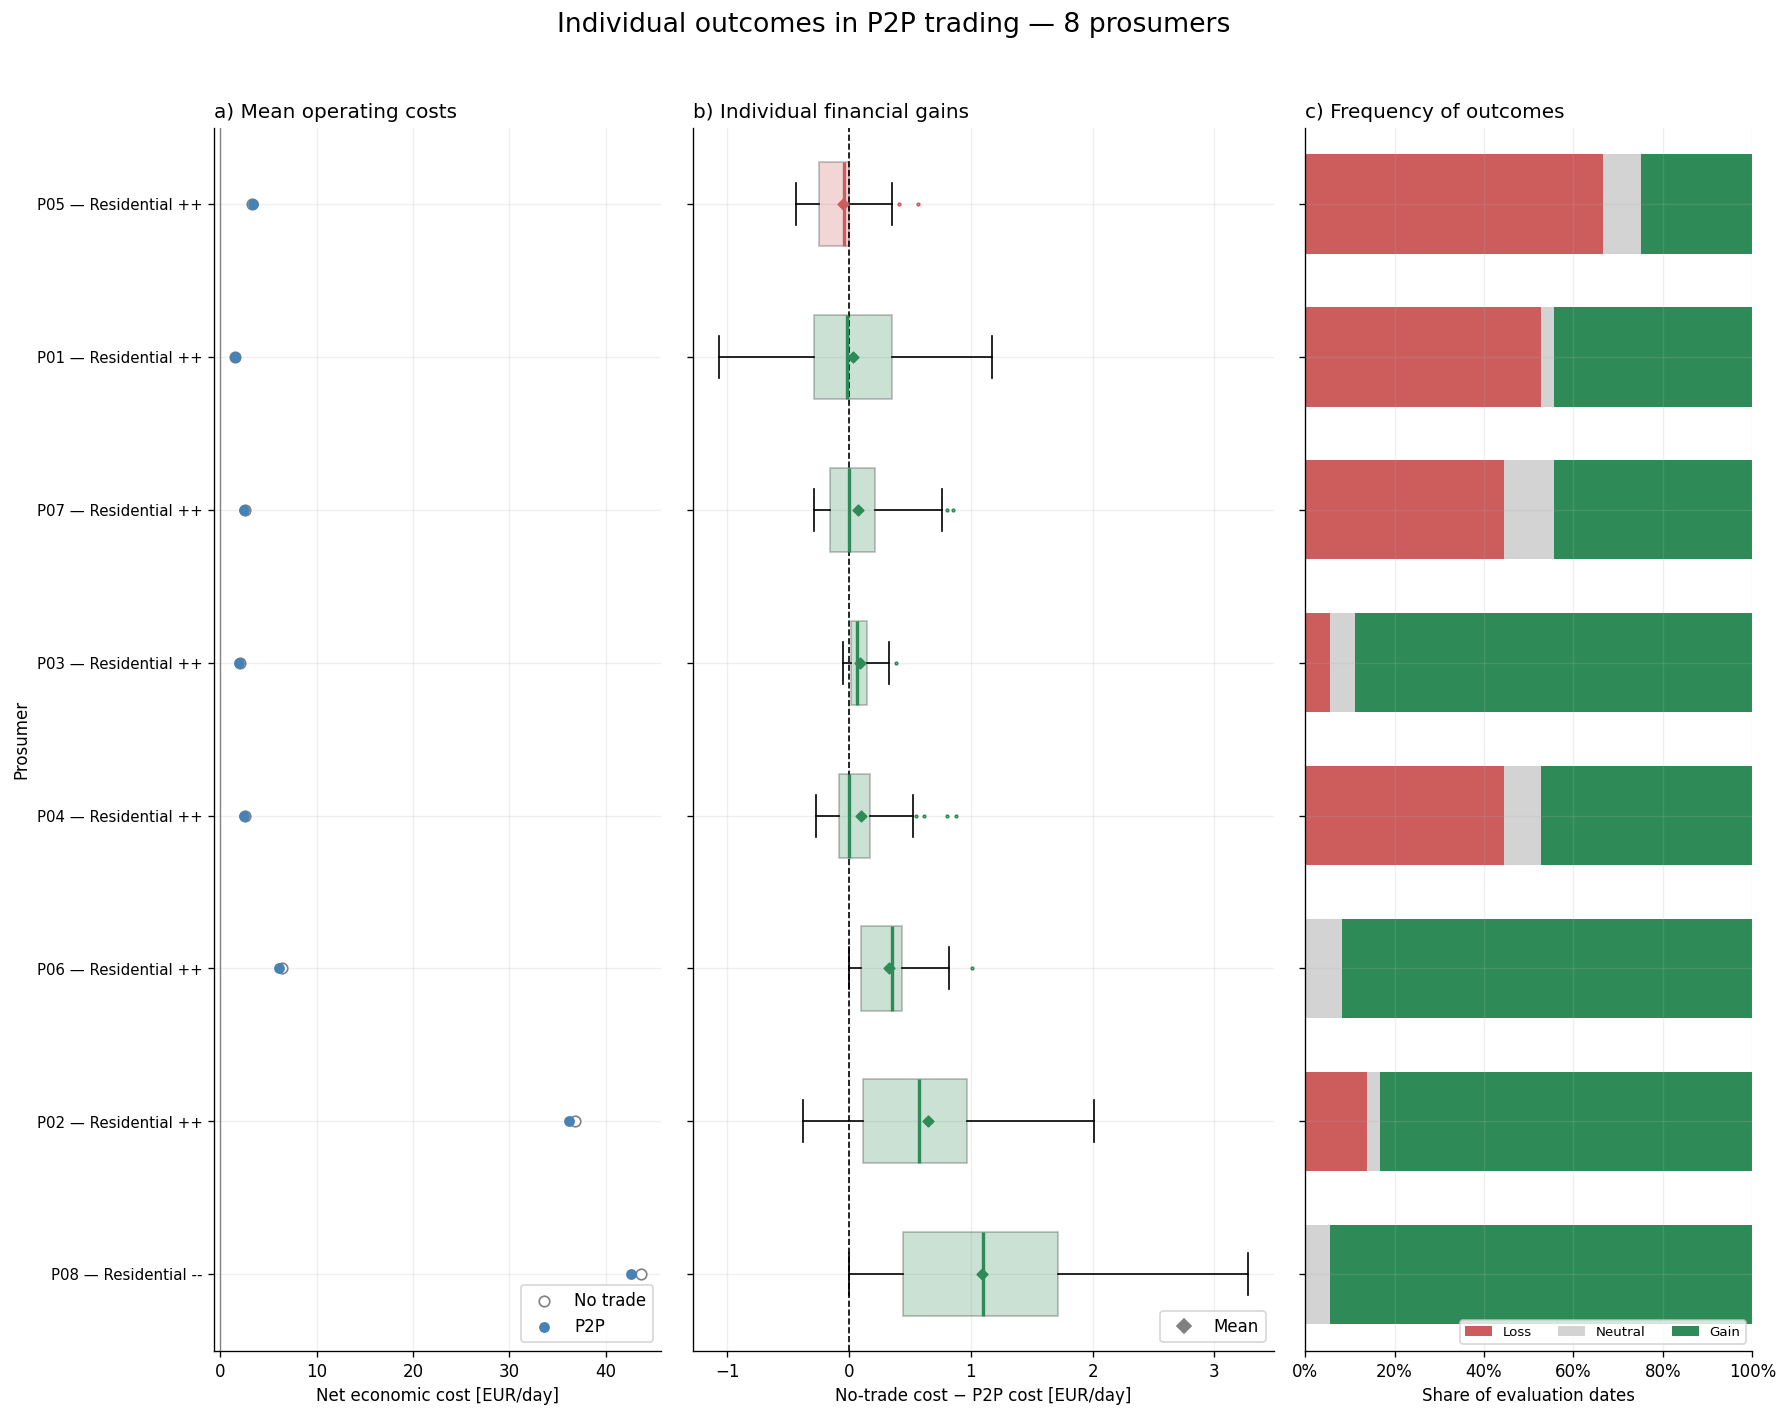

In [34]:
N = 8

sub = df_common[df_common['N'] == N].copy()

# Use the same tolerance as the fairness diagnostics
sub['winner'] = sub['gain'] > TOL
sub['loser'] = sub['gain'] < -TOL
sub['neutral'] = sub['gain'].abs() <= TOL

individual = sub.groupby('prosumer').agg(
    baseline_cost=('J_nt', 'mean'),
    p2p_cost=('J', 'mean'),
    mean_gain=('gain', 'mean'),
    median_gain=('gain', 'median'),
    winner_share=('winner', 'mean'),
    loser_share=('loser', 'mean'),
    neutral_share=('neutral', 'mean')
)

# Sort from most disadvantaged to most benefited
individual = individual.sort_values('mean_gain')

order = individual.index.tolist()
y = np.arange(len(order))

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 12),
    sharey=True,
    gridspec_kw={'width_ratios': [1, 1.3, 1]}
)

# ── A. Costs before and after P2P ─────────────────

ax = axes[0]

ax.hlines(
    y,
    individual['baseline_cost'],
    individual['p2p_cost'],
    color='grey', alpha=0.6
)

ax.scatter(
    individual['baseline_cost'], y,
    facecolors='white',
    edgecolors='grey',
    s=40, label='No trade', zorder=3
)

ax.scatter(
    individual['p2p_cost'], y,
    color='steelblue',
    s=30, label='P2P', zorder=3
)

ax.set_title('a) Mean operating costs', loc='left')
ax.set_xlabel('Net economic cost [EUR/day]')
ax.axvline(0, color='grey', linewidth=0.8)
ax.legend(loc='lower right')


# ── B. Distribution of individual gains ──────────

ax = axes[1]

for pos, p in enumerate(order):

    gains = sub.loc[sub['prosumer'] == p, 'gain'].values

    color = (
        'seagreen'
        if individual.loc[p, 'mean_gain'] >= 0
        else 'indianred'
    )

    ax.boxplot(
        gains,
        positions=[pos],
        vert=False,
        widths=0.55,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.25),
        medianprops=dict(color=color, linewidth=2),
        flierprops=dict(
            marker='.',
            markersize=3,
            markeredgecolor=color
        )
    )

    ax.scatter(
        gains.mean(), pos,
        marker='D', s=20,
        color=color, zorder=4
    )

ax.axvline(0, color='black', linestyle='--', linewidth=1)

ax.set_title('b) Individual financial gains', loc='left')
ax.set_xlabel('No-trade cost − P2P cost [EUR/day]')

ax.legend(
    handles=[
        Line2D([], [], marker='D', linestyle='none',
               color='grey', label='Mean')
    ],
    loc='lower right'
)


# ── C. Frequency of winning and losing ────────────

ax = axes[2]

left = np.zeros(len(individual))

for metric, color, label in [
    ('loser_share', 'indianred', 'Loss'),
    ('neutral_share', 'lightgrey', 'Neutral'),
    ('winner_share', 'seagreen', 'Gain')
]:

    values = individual[metric].values

    ax.barh(
        y, values, left=left,
        color=color, height=0.65,
        label=label
    )

    left += values

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('c) Frequency of outcomes', loc='left')
ax.set_xlabel('Share of evaluation dates')
ax.legend(loc='lower right', ncol=3, fontsize=8)


# ── Shared formatting ─────────────────────────────

axes[0].set_yticks(
    y,
    [prosumer_labels[p] for p in order],
    fontsize=9
)
axes[0].set_ylabel('Prosumer')
axes[0].invert_yaxis()

fig.suptitle(
    f'Individual outcomes in P2P trading — {N} prosumers',
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

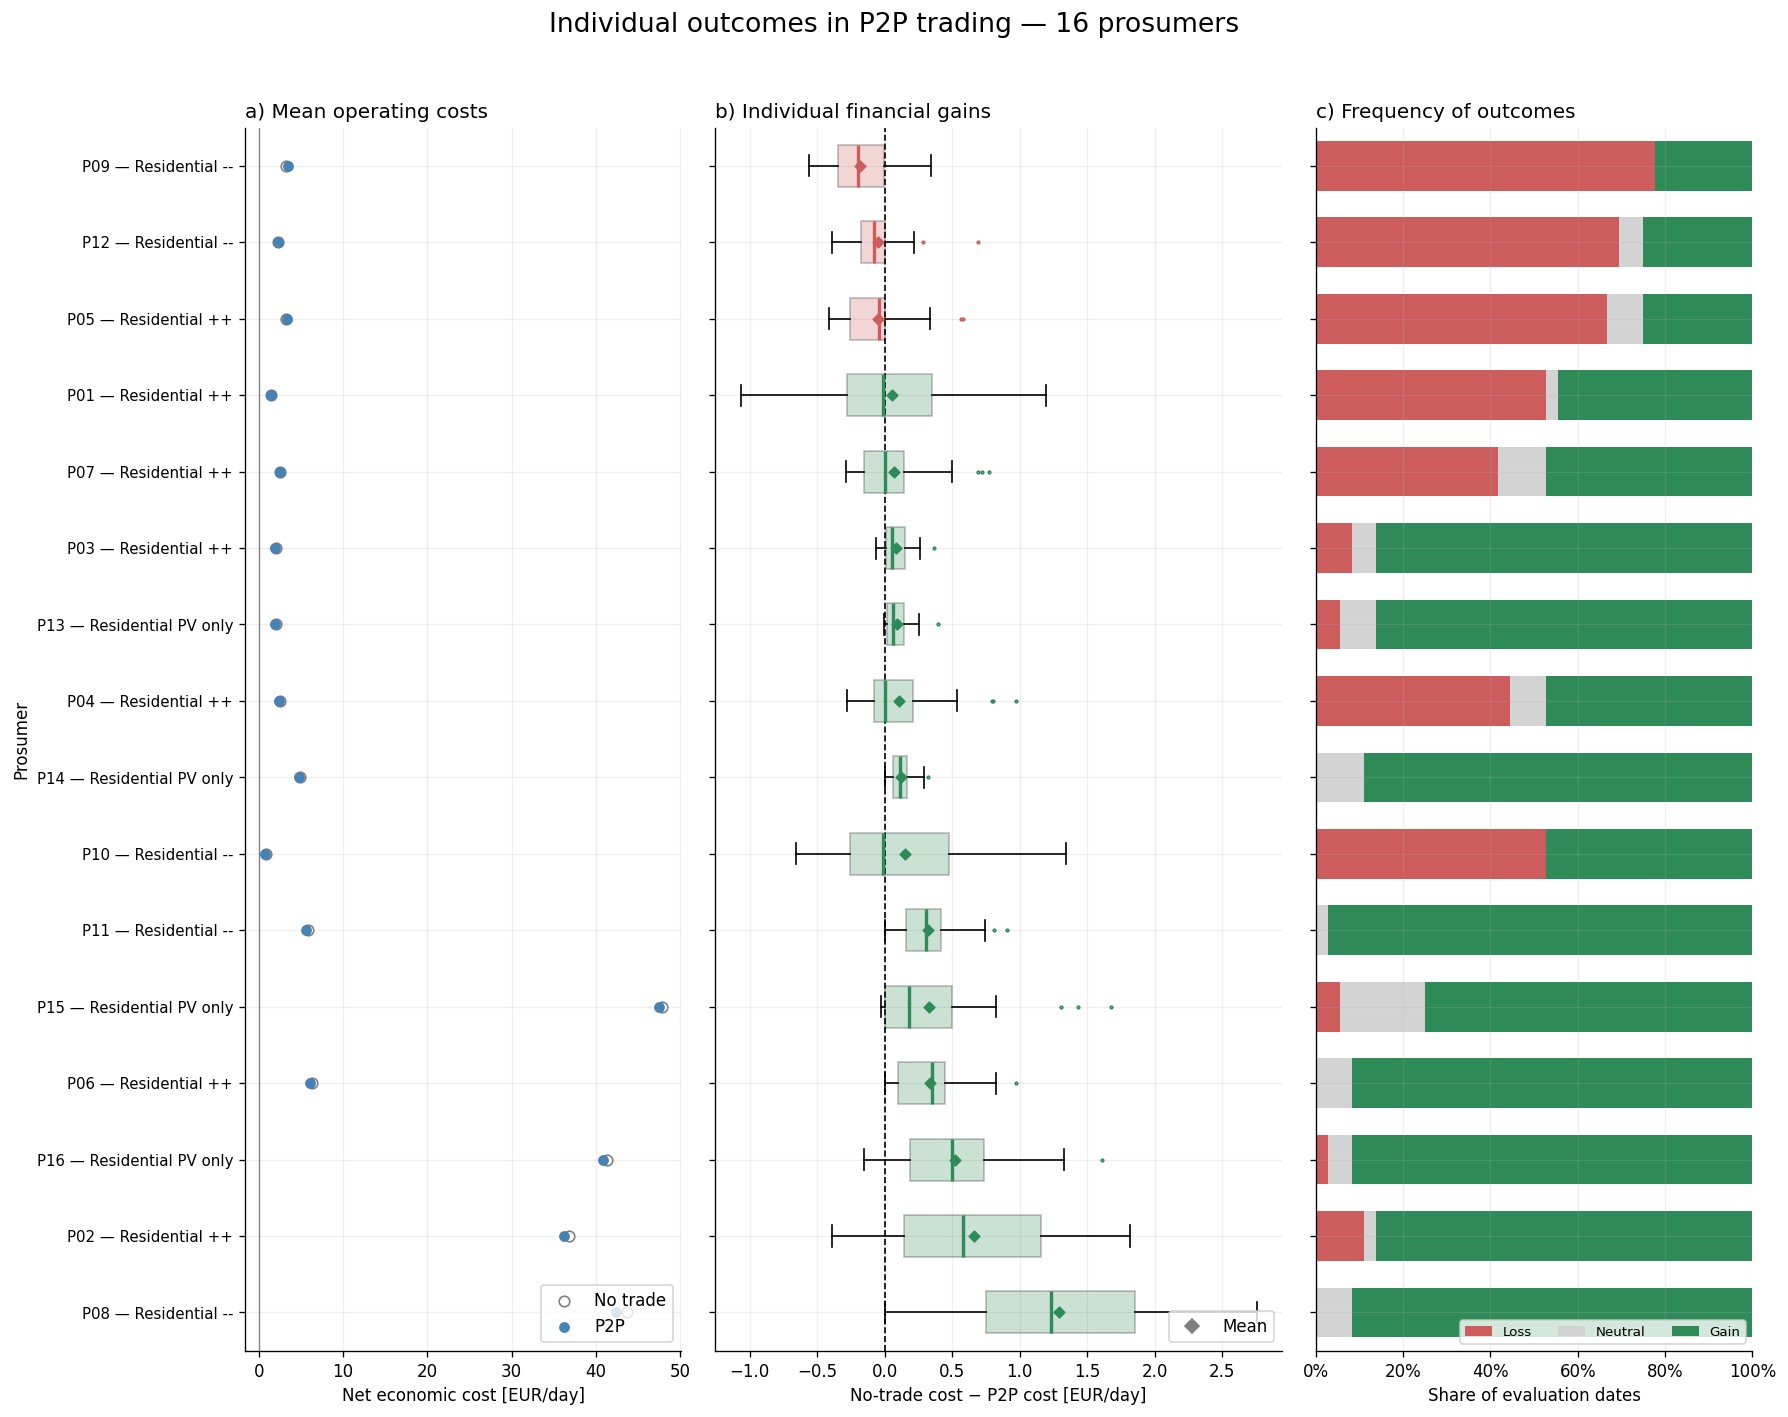

In [33]:
N = 16

sub = df_common[df_common['N'] == N].copy()

# Use the same tolerance as the fairness diagnostics
sub['winner'] = sub['gain'] > TOL
sub['loser'] = sub['gain'] < -TOL
sub['neutral'] = sub['gain'].abs() <= TOL

individual = sub.groupby('prosumer').agg(
    baseline_cost=('J_nt', 'mean'),
    p2p_cost=('J', 'mean'),
    mean_gain=('gain', 'mean'),
    median_gain=('gain', 'median'),
    winner_share=('winner', 'mean'),
    loser_share=('loser', 'mean'),
    neutral_share=('neutral', 'mean')
)

# Sort from most disadvantaged to most benefited
individual = individual.sort_values('mean_gain')

order = individual.index.tolist()
y = np.arange(len(order))

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 12),
    sharey=True,
    gridspec_kw={'width_ratios': [1, 1.3, 1]}
)

# ── A. Costs before and after P2P ─────────────────

ax = axes[0]

ax.hlines(
    y,
    individual['baseline_cost'],
    individual['p2p_cost'],
    color='grey', alpha=0.6
)

ax.scatter(
    individual['baseline_cost'], y,
    facecolors='white',
    edgecolors='grey',
    s=40, label='No trade', zorder=3
)

ax.scatter(
    individual['p2p_cost'], y,
    color='steelblue',
    s=30, label='P2P', zorder=3
)

ax.set_title('a) Mean operating costs', loc='left')
ax.set_xlabel('Net economic cost [EUR/day]')
ax.axvline(0, color='grey', linewidth=0.8)
ax.legend(loc='lower right')


# ── B. Distribution of individual gains ──────────

ax = axes[1]

for pos, p in enumerate(order):

    gains = sub.loc[sub['prosumer'] == p, 'gain'].values

    color = (
        'seagreen'
        if individual.loc[p, 'mean_gain'] >= 0
        else 'indianred'
    )

    ax.boxplot(
        gains,
        positions=[pos],
        vert=False,
        widths=0.55,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.25),
        medianprops=dict(color=color, linewidth=2),
        flierprops=dict(
            marker='.',
            markersize=3,
            markeredgecolor=color
        )
    )

    ax.scatter(
        gains.mean(), pos,
        marker='D', s=20,
        color=color, zorder=4
    )

ax.axvline(0, color='black', linestyle='--', linewidth=1)

ax.set_title('b) Individual financial gains', loc='left')
ax.set_xlabel('No-trade cost − P2P cost [EUR/day]')

ax.legend(
    handles=[
        Line2D([], [], marker='D', linestyle='none',
               color='grey', label='Mean')
    ],
    loc='lower right'
)


# ── C. Frequency of winning and losing ────────────

ax = axes[2]

left = np.zeros(len(individual))

for metric, color, label in [
    ('loser_share', 'indianred', 'Loss'),
    ('neutral_share', 'lightgrey', 'Neutral'),
    ('winner_share', 'seagreen', 'Gain')
]:

    values = individual[metric].values

    ax.barh(
        y, values, left=left,
        color=color, height=0.65,
        label=label
    )

    left += values

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('c) Frequency of outcomes', loc='left')
ax.set_xlabel('Share of evaluation dates')
ax.legend(loc='lower right', ncol=3, fontsize=8)


# ── Shared formatting ─────────────────────────────

axes[0].set_yticks(
    y,
    [prosumer_labels[p] for p in order],
    fontsize=9
)
axes[0].set_ylabel('Prosumer')
axes[0].invert_yaxis()

fig.suptitle(
    f'Individual outcomes in P2P trading — {N} prosumers',
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

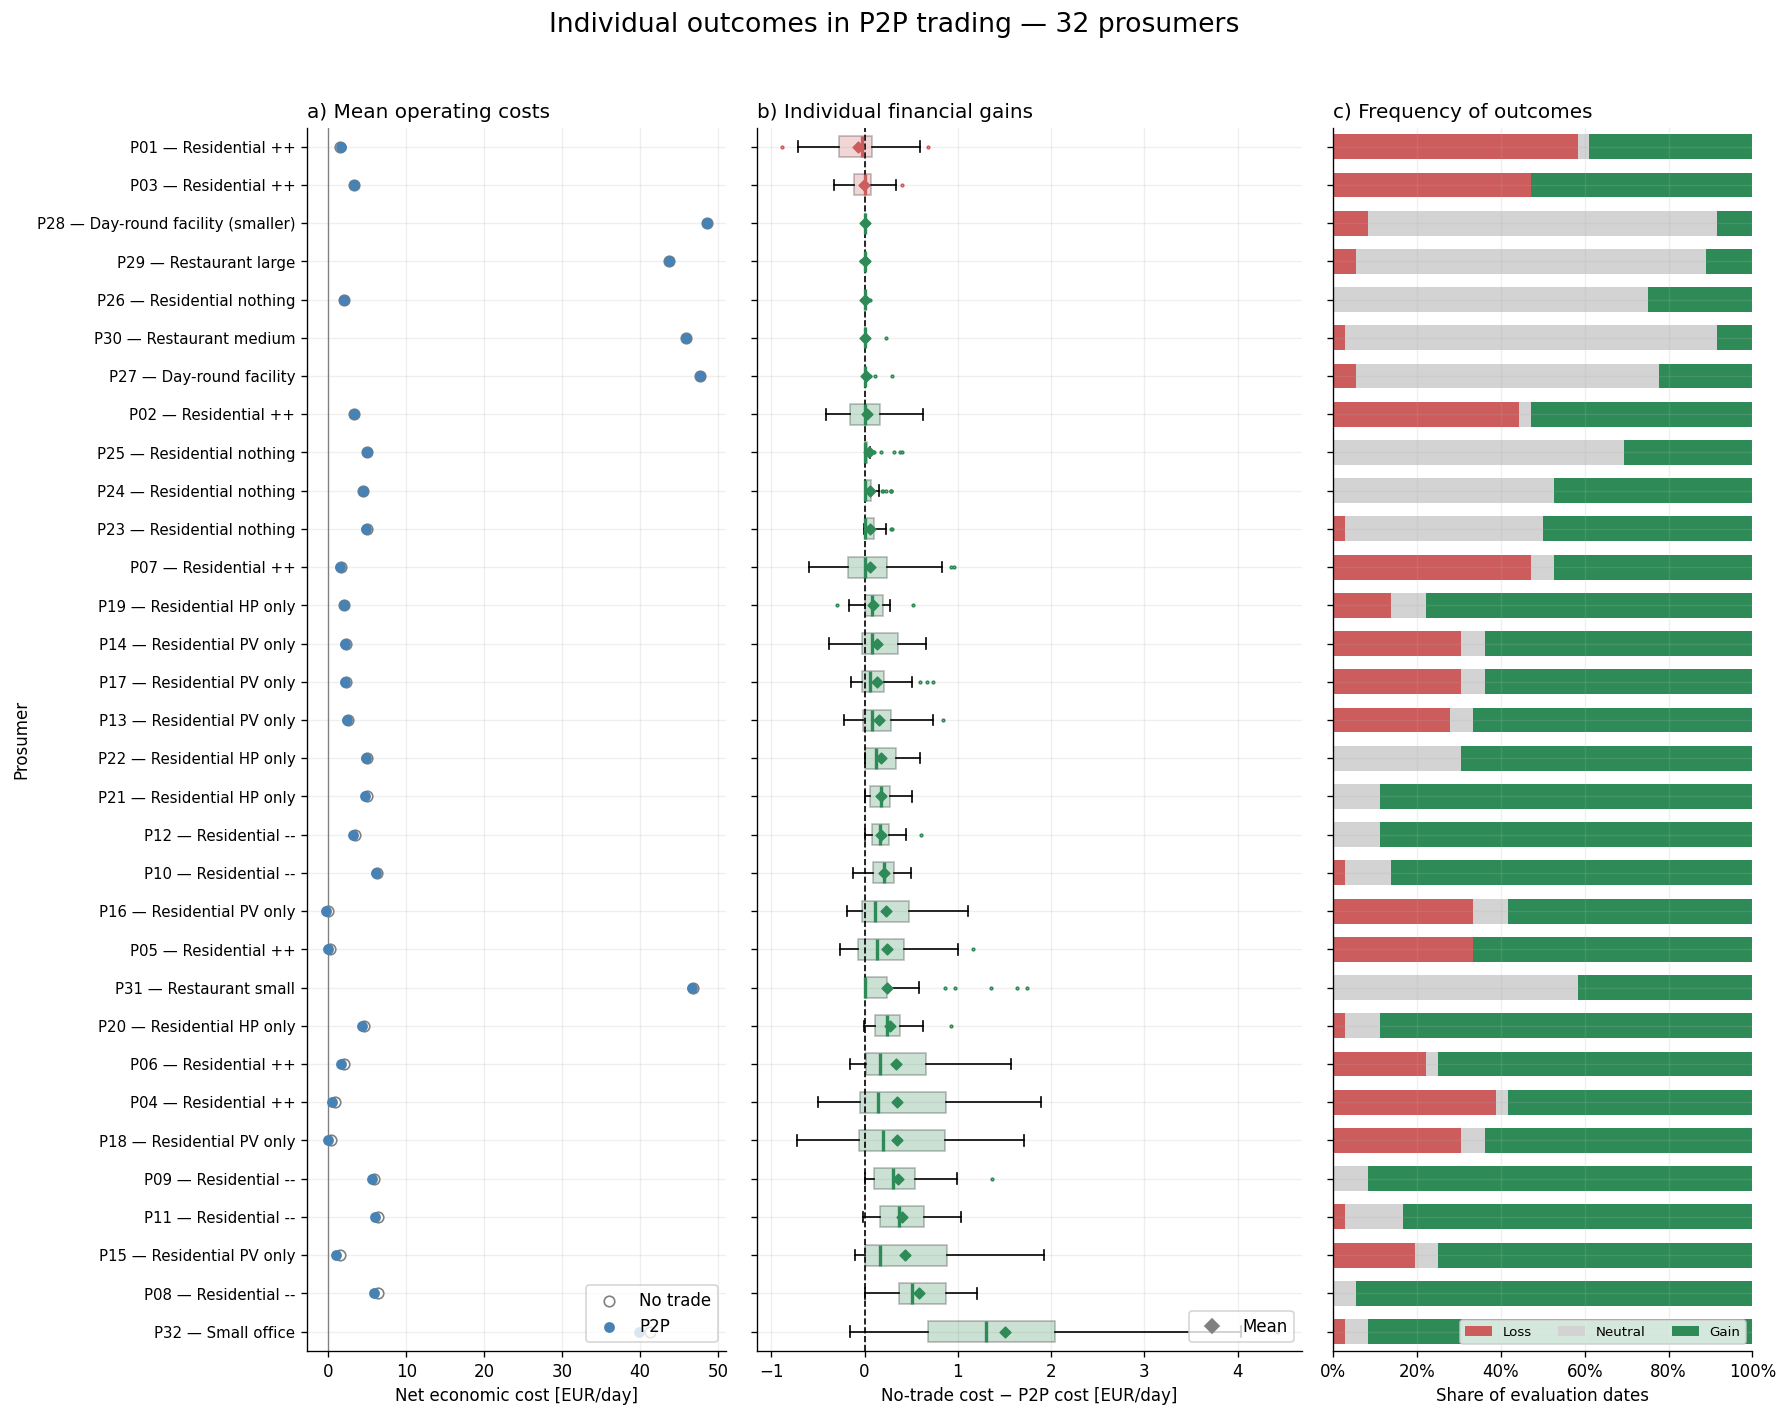

In [29]:
N = 32

sub = df_common[df_common['N'] == N].copy()

# Use the same tolerance as the fairness diagnostics
sub['winner'] = sub['gain'] > TOL
sub['loser'] = sub['gain'] < -TOL
sub['neutral'] = sub['gain'].abs() <= TOL

individual = sub.groupby('prosumer').agg(
    baseline_cost=('J_nt', 'mean'),
    p2p_cost=('J', 'mean'),
    mean_gain=('gain', 'mean'),
    median_gain=('gain', 'median'),
    winner_share=('winner', 'mean'),
    loser_share=('loser', 'mean'),
    neutral_share=('neutral', 'mean')
)

# Sort from most disadvantaged to most benefited
individual = individual.sort_values('mean_gain')

order = individual.index.tolist()
y = np.arange(len(order))

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 12),
    sharey=True,
    gridspec_kw={'width_ratios': [1, 1.3, 1]}
)

# ── A. Costs before and after P2P ─────────────────

ax = axes[0]

ax.hlines(
    y,
    individual['baseline_cost'],
    individual['p2p_cost'],
    color='grey', alpha=0.6
)

ax.scatter(
    individual['baseline_cost'], y,
    facecolors='white',
    edgecolors='grey',
    s=40, label='No trade', zorder=3
)

ax.scatter(
    individual['p2p_cost'], y,
    color='steelblue',
    s=30, label='P2P', zorder=3
)

ax.set_title('a) Mean operating costs', loc='left')
ax.set_xlabel('Net economic cost [EUR/day]')
ax.axvline(0, color='grey', linewidth=0.8)
ax.legend(loc='lower right')


# ── B. Distribution of individual gains ──────────

ax = axes[1]

for pos, p in enumerate(order):

    gains = sub.loc[sub['prosumer'] == p, 'gain'].values

    color = (
        'seagreen'
        if individual.loc[p, 'mean_gain'] >= 0
        else 'indianred'
    )

    ax.boxplot(
        gains,
        positions=[pos],
        vert=False,
        widths=0.55,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.25),
        medianprops=dict(color=color, linewidth=2),
        flierprops=dict(
            marker='.',
            markersize=3,
            markeredgecolor=color
        )
    )

    ax.scatter(
        gains.mean(), pos,
        marker='D', s=20,
        color=color, zorder=4
    )

ax.axvline(0, color='black', linestyle='--', linewidth=1)

ax.set_title('b) Individual financial gains', loc='left')
ax.set_xlabel('No-trade cost − P2P cost [EUR/day]')

ax.legend(
    handles=[
        Line2D([], [], marker='D', linestyle='none',
               color='grey', label='Mean')
    ],
    loc='lower right'
)


# ── C. Frequency of winning and losing ────────────

ax = axes[2]

left = np.zeros(len(individual))

for metric, color, label in [
    ('loser_share', 'indianred', 'Loss'),
    ('neutral_share', 'lightgrey', 'Neutral'),
    ('winner_share', 'seagreen', 'Gain')
]:

    values = individual[metric].values

    ax.barh(
        y, values, left=left,
        color=color, height=0.65,
        label=label
    )

    left += values

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('c) Frequency of outcomes', loc='left')
ax.set_xlabel('Share of evaluation dates')
ax.legend(loc='lower right', ncol=3, fontsize=8)


# ── Shared formatting ─────────────────────────────

axes[0].set_yticks(
    y,
    [prosumer_labels[p] for p in order],
    fontsize=9
)
axes[0].set_ylabel('Prosumer')
axes[0].invert_yaxis()

fig.suptitle(
    f'Individual outcomes in P2P trading — {N} prosumers',
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

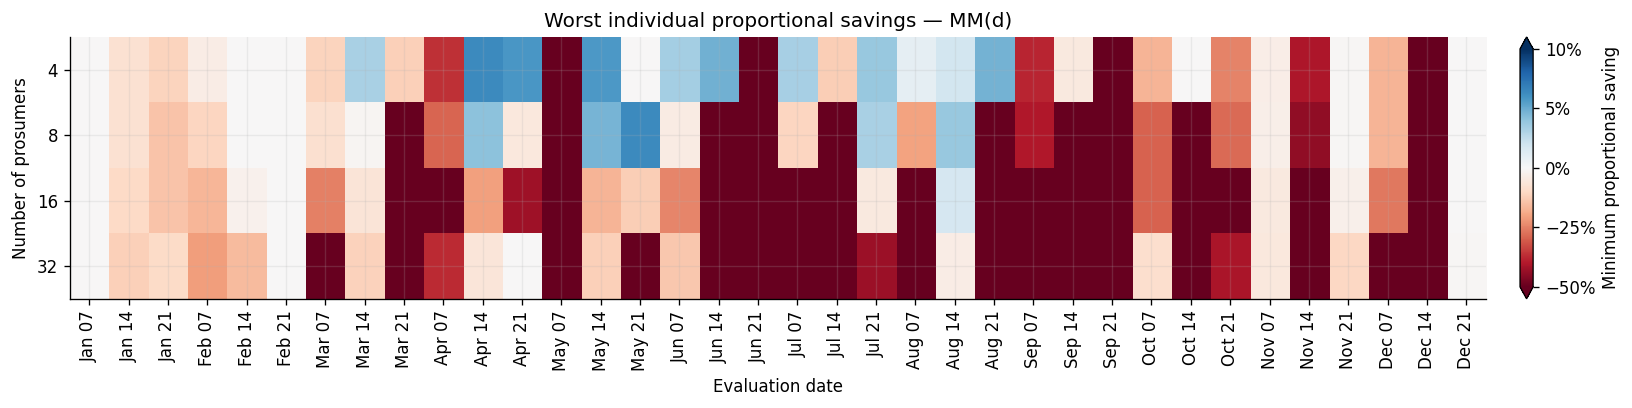

In [31]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import PercentFormatter

pivot = (
    daily_common
    .pivot(index='N', columns='date', values='d_MM')
    .reindex(POPULATIONS)
)

fig, ax = plt.subplots(figsize=(15, 3.5))

im = ax.imshow(
    pivot.values,
    aspect='auto',
    cmap='RdBu',
    interpolation='nearest',
    norm=TwoSlopeNorm(
        vmin=-0.5,
        vcenter=0,
        vmax=0.1
    )
)

ax.set_yticks(range(len(pivot.index)), pivot.index)

ax.set_xticks(
    range(len(pivot.columns)),
    pivot.columns.strftime('%b %d'),
    rotation=90
)

ax.set_ylabel('Number of prosumers')
ax.set_xlabel('Evaluation date')
ax.set_title('Worst individual proportional savings — MM(d)')

cbar = fig.colorbar(im, ax=ax, pad=0.02, extend='both')
cbar.set_ticks([-0.5, -0.25, 0, 0.05, 0.1])
cbar.ax.yaxis.set_major_formatter(PercentFormatter(1))
cbar.set_label('Minimum proportional saving')

plt.tight_layout()
plt.show()

## Aggregate economic benefits and losses

To investigate the economic benefits of P2P trading
and their distribution among prosumers, the absolute
cost improvements are separated into positive gains
and individual losses.

### Total benefits

The sum of cost improvements among prosumers who
benefit from P2P trading:

$$
B(x) = \sum_{i\in\mathcal{I}}
\max\left\{J_i(\hat{x})-J_i(x),0\right\}
$$

### Total losses

The sum of additional costs incurred by prosumers
who are disadvantaged by P2P trading:

$$
L(x) = \sum_{i\in\mathcal{I}}
\max\left\{J_i(x)-J_i(\hat{x}),0\right\}
$$

### Net economic benefit

The difference between total benefits and total losses:

$$
S(x)=B(x)-L(x)
$$

Equivalently,

$$
S(x)=\sum_{i\in\mathcal{I}}J_i(\hat{x})
-\sum_{i\in\mathcal{I}}J_i(x)
$$

This corresponds to the absolute rather than
relative total welfare improvement:

$$
TW(x)=\frac{S(x)}
{\sum_{i\in\mathcal{I}}J_i(\hat{x})}
$$

### Potential for compensation

If

$$
B(x)\geq L(x),
$$

the economic benefits generated by P2P trading are
sufficient to fully compensate disadvantaged
prosumers through budget-balanced financial transfers.

The figure presents the arithmetic mean of daily
benefits and losses across the 36 evaluation dates
for each population size.

,total_benefits,total_losses,net_benefit,compensation_feasible
N,,,,
4,1.33855,0.16710,1.17145,0.97222
8,2.73715,0.42520,2.31195,1.00000
16,4.72405,0.87316,3.85089,0.97222
32,7.51557,0.76623,6.74934,1.00000


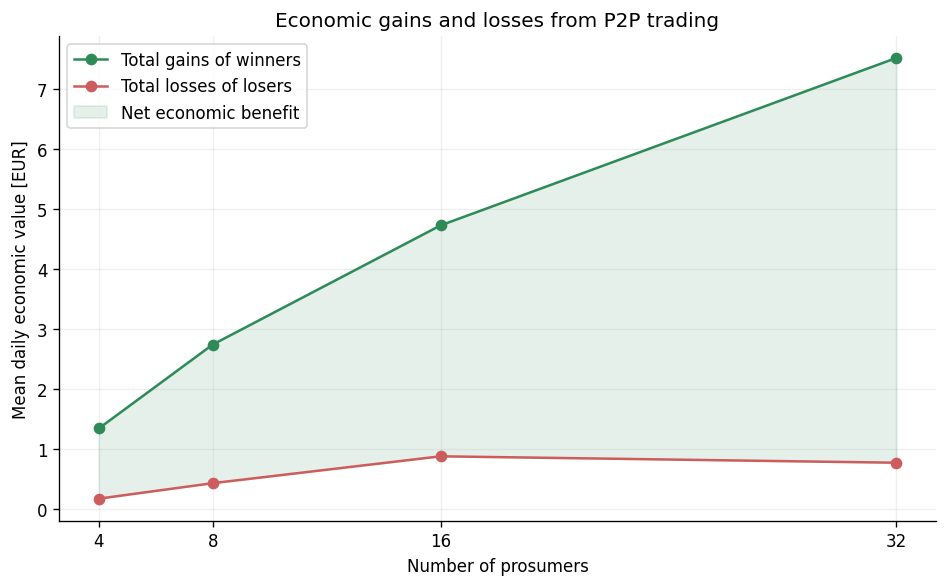

In [32]:
redistribution = (
    df_common
    .assign(
        positive_gain=lambda x: x['gain'].clip(lower=0),
        financial_loss=lambda x: -x['gain'].clip(upper=0)
    )
    .groupby(['N', 'date'])
    .agg(
        total_benefits=('positive_gain', 'sum'),
        total_losses=('financial_loss', 'sum')
    )
    .reset_index()
)

redistribution['net_benefit'] = (
    redistribution['total_benefits']
    - redistribution['total_losses']
)

redistribution['compensation_feasible'] = (
    redistribution['net_benefit'] >= -TOL
)

display(redistribution.groupby('N').mean(numeric_only=True))

fig, ax = plt.subplots(figsize=(8, 5))

stats = redistribution.groupby('N').mean(numeric_only=True)

ax.plot(
    stats.index, stats['total_benefits'],
    'o-', color='seagreen',
    label='Total gains of winners'
)

ax.plot(
    stats.index, stats['total_losses'],
    'o-', color='indianred',
    label='Total losses of losers'
)

ax.fill_between(
    stats.index,
    stats['total_losses'],
    stats['total_benefits'],
    color='seagreen', alpha=0.12,
    label='Net economic benefit'
)

ax.set_xticks(POPULATIONS)
ax.set_xlabel('Number of prosumers')
ax.set_ylabel('Mean daily economic value [EUR]')
ax.set_title('Economic gains and losses from P2P trading')
ax.legend()

plt.tight_layout()
plt.show()

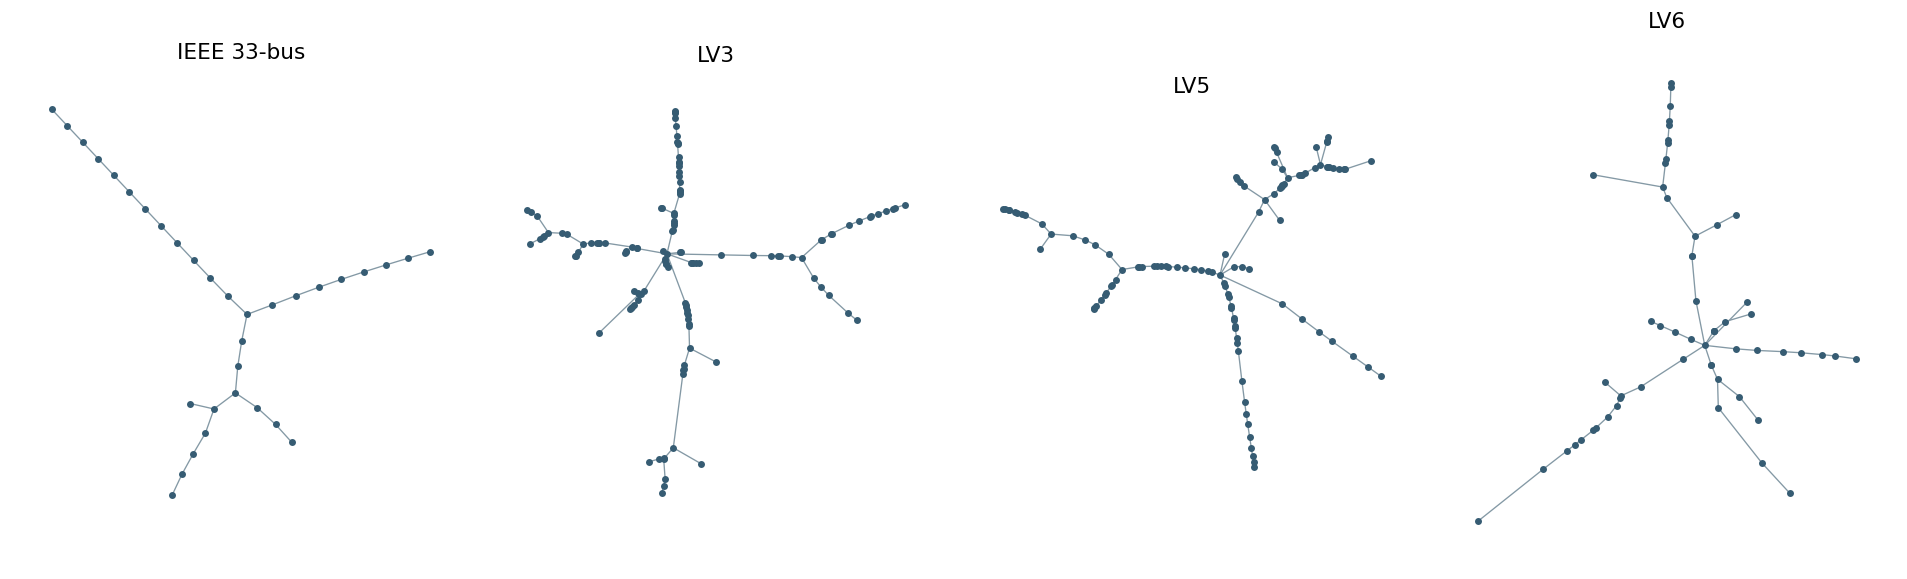

In [44]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, (name, net) in zip(axes, networks.items()):

    G = nx.Graph(top.create_nxgraph(
        net,
        respect_switches=True
    ))

    # Retain only the distribution network
    if name != 'IEEE 33-bus':
        lv_buses = net.bus.index[net.bus.vn_kv <= 1.0]
        G = G.subgraph(lv_buses).copy()

    pos = nx.kamada_kawai_layout(G)

    nx.draw_networkx(
        G, pos, ax=ax,
        node_size=10,
        node_color='#365c73',
        edge_color='#8499a5',
        width=0.8,
        with_labels=False
    )

    ax.set_title(name, fontsize=13)
    ax.set_aspect('equal')
    ax.set_axis_off()

plt.tight_layout()
plt.show()